In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import seaborn as sns
import math
from scipy import signal
import seaborn as sns
import seaborn as sns
import h5py
from scipy.stats import zscore
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from scipy.stats import ks_2samp
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.svm import SVR
from sklearn.model_selection import cross_val_score, KFold
from matplotlib import cm
from matplotlib.colors import Normalize

In [112]:
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/DR_Trapezoid_VL.jld2"

with h5py.File(file_path, 'r') as f:
    spike_array = f['spike_array'][:]


/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_6543/2588129002.py:27: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f'{int(x_tick / 20000):,}' for x_tick in x_ticks], fontsize=15, fontweight='bold')


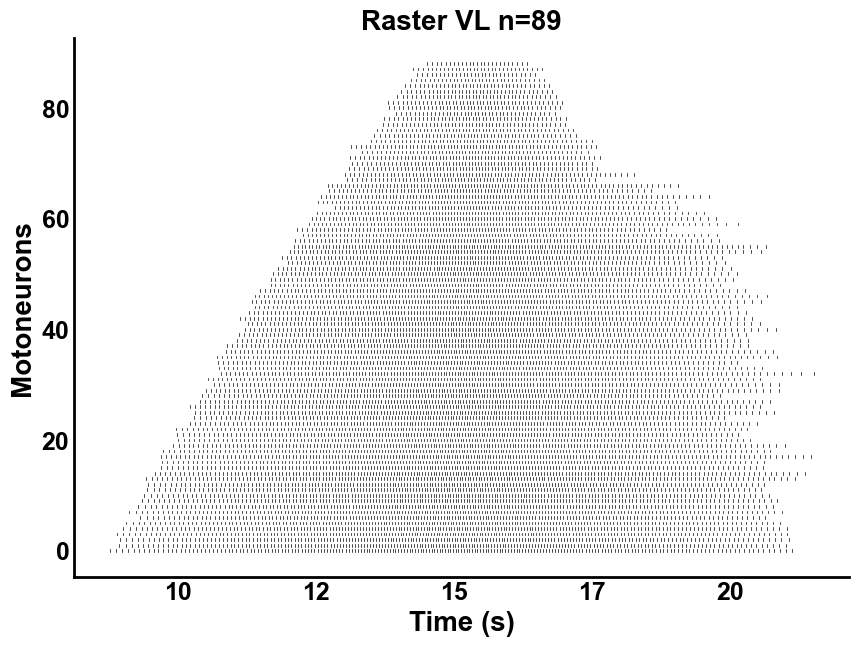

In [113]:
n_times, n_neurons = spike_array.shape

plt.rcParams['font.family'] = 'Arial'

fig, ax = plt.subplots(figsize=(10, 7))

line_height = 0.5
line_thickness = 0.5

horizontal_offset = 100  # Adjust this value as needed to separate the spikes

# Plot spikes
for neuron in range(n_neurons):
    for t in range(n_times):
        if spike_array[t, neuron] == 1.0:
            # Add a small horizontal offset to each spike for separation
            x_offset = horizontal_offset * neuron
            ax.plot([t + x_offset, t + x_offset], [neuron - line_height / 2, neuron + line_height / 2], 
                    color='black', linewidth=line_thickness)

# Set axis labels
ax.set_xlabel("Time (s)",fontsize=20, fontweight='bold')
ax.set_ylabel("Motoneurons",fontsize=20, fontweight='bold')
ax.set_title("Raster VL n=89",fontsize=20, fontweight='bold')

x_ticks = ax.get_xticks()  # Get current tick locations
ax.set_xticklabels([f'{int(x_tick / 20000):,}' for x_tick in x_ticks], fontsize=15, fontweight='bold')

# Hide grid lines
ax.grid(False)

plt.xticks(fontsize=18, fontweight='bold')
plt.yticks(fontsize=18, fontweight='bold')

# Remove all spines
sns.despine()  # Removes all spines except the bottom and left (optional, modify as needed)

ax.tick_params(axis='both', length=0)

# Save the figure in high quality
ax = plt.gca()  # Get current axis
ax.spines['bottom'].set_linewidth(2)  # Make bottom axis thicker
ax.spines['left'].set_linewidth(2)  

# Show the plot
plt.savefig('/Users/nmt121/Desktop/figures/RasterVL_89MN.png', dpi=300, bbox_inches='tight')



# Show the plot
plt.show()


In [121]:
file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/allratesVL.jld2"

with h5py.File(file_path, 'r') as f:
    all_rates = f['new_all_rates'][:]

file_path = "/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/alltimebasesVL.jld2"

with h5py.File(file_path, 'r') as f:
    all_timebases = f['new_all_bases'][:]


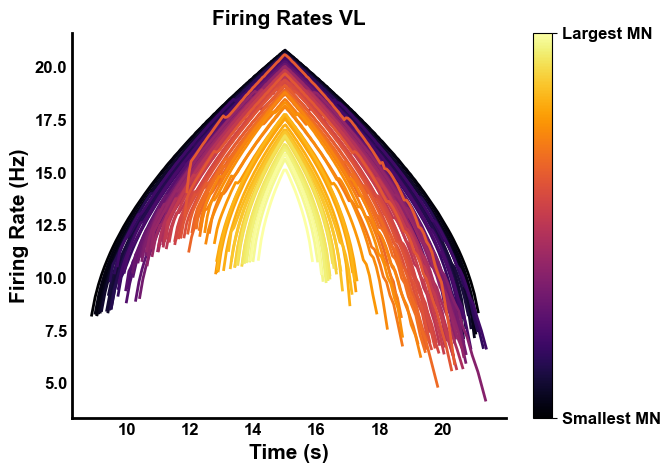

In [124]:

# Create a color map using inferno and then discretize it into 87 colors
cmap = plt.get_cmap('inferno')
discrete_cmap = cmap(np.linspace(0, 1, 89))

# Normalize the color range based on the number of motor neurons (87)
norm = Normalize(vmin=0, vmax=88)

# Create a figure and axis
fig, ax = plt.subplots(figsize=(7, 5))

# Plot each firing rate time series with corresponding color
for i in range(89):
    ax.plot(all_timebases[:, i], all_rates[:, i], color=discrete_cmap[i], linewidth=2)

# Set labels and title with Arial font
ax.set_xlabel("Time (s)", fontsize=15, fontweight='bold', fontname='Arial')
ax.set_ylabel("Firing Rate (Hz)", fontsize=15, fontweight='bold', fontname='Arial')
ax.set_title("Firing Rates VL", fontsize=15, fontweight='bold', fontname='Arial')

# Customize ticks with Arial font and remove tick marks
ax.tick_params(axis='both', length=0)
plt.xticks(fontsize=12, fontweight='bold', fontname='Arial')
plt.yticks(fontsize=12, fontweight='bold', fontname='Arial')

# Hide grid lines
ax.grid(False)

# Remove all spines except bottom and left
import seaborn as sns
sns.despine()

# Set the linewidth of the bottom and left spines
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)

# Create the color bar
sm = plt.cm.ScalarMappable(cmap=plt.get_cmap('inferno'), norm=norm)
sm.set_array([])  # The array is just for the color bar, can be left empty

# Add the color bar to the plot
cbar = plt.colorbar(sm, ax=ax)

# Set the color bar ticks to display only two values
cbar.set_ticks([0, 88])
cbar.set_ticklabels(['Smallest MN', 'Largest MN'],fontsize=12, fontweight='bold', fontname='Arial')

# Move the color bar label closer and set the vertical alignment
# cbar.set_label('Motoneuron', fontsize=12, fontweight='bold', fontname='Arial', labelpad=-40)


# Save the figure in high quality
plt.savefig('/Users/nmt121/Desktop/figures/FiringRatesComparisonVL.png', dpi=300, bbox_inches='tight')

# Show the plot
plt.show()
